## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Thaliana Rocio Sierra Garcia" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
Una empresa debe administrar tareas técnicas según su prioridad y conectar varios dispositivos utilizando la menor cantidad total de cable, el sistema debe construir el Heap, mostrar su arreglo y representación en árbol, procesar las dos tareas de mayor prioridad mediante EXTRACT-MAX y posteriormente insertar la tarea T07, de prioridad 12

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

**REQUERIMIENTOS FUNCIONALES**

**RF01**. Registrar las seis tareas del enunciado con código, descripción y prioridad

**RF02**. Construir una cola de prioridad máxima utilizando un Max-Heap

**RF03**. Implementar Max-heapify para mantener la propiedad de Max-Heap

**RF04**. Generar una gráfica final con los seis dispositivos, solo las conexiones del MST, el peso de cada conexión y la longitud total

**REQUERIMIENTOS NO FUNCIONALES** 

**RF01**. Desarrollar toda la solución en un único Notebook de Jupyter

**RNF02**. Mantener el código organizado, legible y documentado

**RNF03**Implementar manualmente los algoritmos solicitados

**RNF04** No utilizar `heapq` ni funciones de librerías que calculen directamente el MST




## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.

**HU01**. Procesamiento e insercción de tareas

criterios de aceptación:

-Se implementa EXTRACT-MAX

-Se procesan las dos tareas de mayor prioridad

-Se muestra el Heap después de cada extracción

-Se inserta T07 con prioridad 12 y se muestra el Heap reorganizado

-No se utiliza heapq


**HU02**. Optimización de las conexiones

criterios de aceptación:

-Se ordenan las aristas por peso

-Se implementa manualmente el algoritmo de Kruskal

-Se descartan las aristas que formen ciclos

-El MST contiene exactamente cinco conexiones

-Se calcula la longitud total del cable



**HU03**. Construcción de la cola de prioridad

criterios de aceptación: 

-Se registran las seis tareas indicadas en el enunciado

-Se implementan MAX-HEAPIFY y BUILD-MAX-HEAP

-Se muestra el arreglo inicial, el Max-Heap resultante y su representación en árbol


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

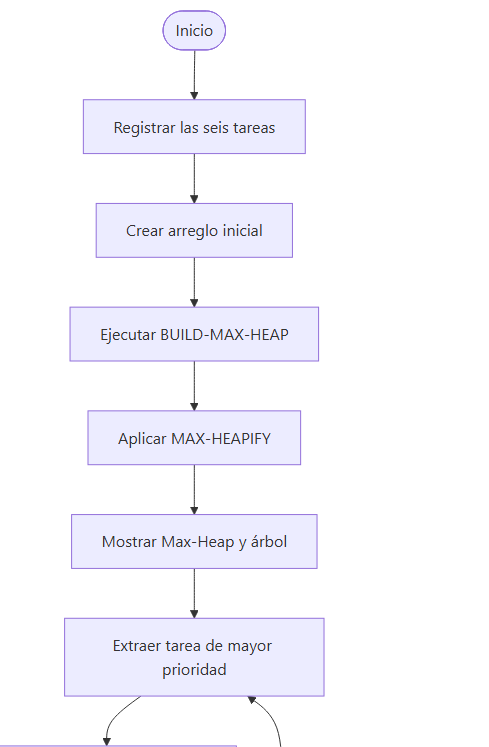
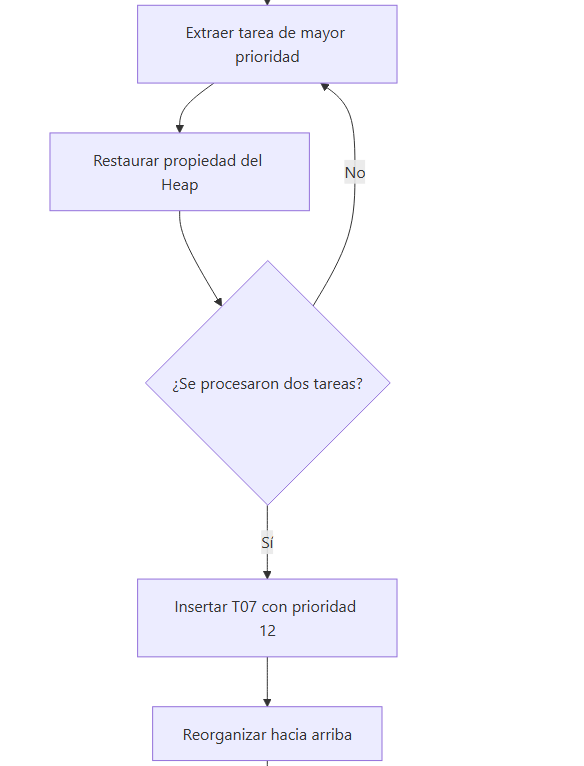
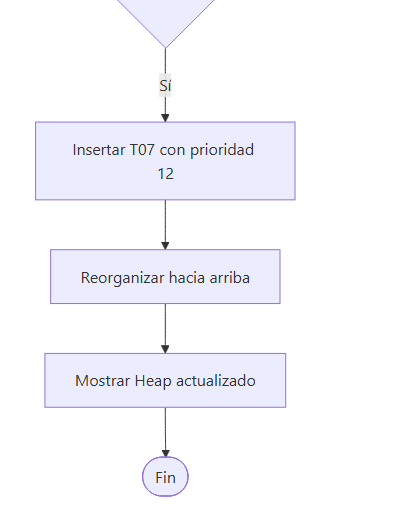


Adjunta imagen y descríbelo claramente.


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.

PUNTO 1


In [1]:
import math
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110


In [2]:
tareas = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor",      10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara",      8),
    ("T05", "Generar respaldo",    3),
    ("T06", "Configurar alarma",   7),
]


arreglo_inicial = [(p, c, t) for c, t, p in tareas]

def fmt(heap):
    """Formato legible del arreglo: [T01:6, T02:10, ...]"""
    return "[" + ", ".join(f"{c}:{p}" for p, c, _ in heap) + "]"


def izquierdo(i): return 2 * i + 1
def derecho(i):   return 2 * i + 2
def padre(i):     return (i - 1) // 2

In [3]:
def max_heapify(A, i, heap_size):
    """MAX-HEAPIFY: hunde A[i] hasta que se cumpla la propiedad de Max-Heap en su subárbol."""
    l, r = izquierdo(i), derecho(i)
    mayor = i
    if l < heap_size and A[l][0] > A[mayor][0]:   
        mayor = l
    if r < heap_size and A[r][0] > A[mayor][0]:  
        mayor = r
    if mayor != i:                               
        A[i], A[mayor] = A[mayor], A[i]
        max_heapify(A, mayor, heap_size)


def build_max_heap(A, verbose=False):
    """BUILD-MAX-HEAP: convierte un arreglo cualquiera en Max-Heap (in place)."""
    n = len(A)
    for i in range(n // 2 - 1, -1, -1):          
        max_heapify(A, i, n)
        if verbose:
            print(f"  max_heapify en i={i}: {fmt(A)}")


def es_max_heap(A):
    """Verificación: A[padre(i)] >= A[i] para todo i > 0."""
    return all(A[padre(i)][0] >= A[i][0] for i in range(1, len(A)))

In [4]:
def dibujar_heap(A, titulo="Heap"):
    """Dibuja el heap como árbol binario (cada nodo: código y prioridad)."""
    n = len(A)
    niveles = int(math.log2(n)) + 1 if n else 1
    pos = {}
    for i in range(n):
        nivel = int(math.log2(i + 1))
        k = i - (2 ** nivel - 1)                       
        pos[i] = ((k + 0.5) / 2 ** nivel, -nivel)

    fig, ax = plt.subplots(figsize=(7, 1.2 + 1.3 * niveles))
    for i in range(1, n):                              
        x1, y1 = pos[padre(i)]; x2, y2 = pos[i]
        ax.plot([x1, x2], [y1, y2], color="gray", zorder=1)
    for i in range(n):                                
        x, y = pos[i]
        p, c, _ = A[i]
        ax.scatter(x, y, s=1500, color="#cfe8ff" if i else "#ffd9a0", edgecolor="black", zorder=2)
        ax.text(x, y, f"{c}\n{p}", ha="center", va="center", fontsize=9, zorder=3)
        ax.text(x + 0.035, y + 0.28, f"i={i}", fontsize=7, color="gray")
    ax.set_title(titulo)
    ax.axis("off")
    ax.set_ylim(-niveles + 0.4, 0.6)
    ax.set_xlim(-0.08, 1.08)
    plt.show()


def mostrar_heap(A, titulo):
    print(f"{titulo}")
    print("  Arreglo:", fmt(A))
    print("  ¿Cumple propiedad Max-Heap?", es_max_heap(A))
    dibujar_heap(A, titulo)

ARREGLO INICIAL (sin ordenar como heap)
  Arreglo: [T01:6, T02:10, T03:4, T04:8, T05:3, T06:7]
  ¿Cumple propiedad Max-Heap? False


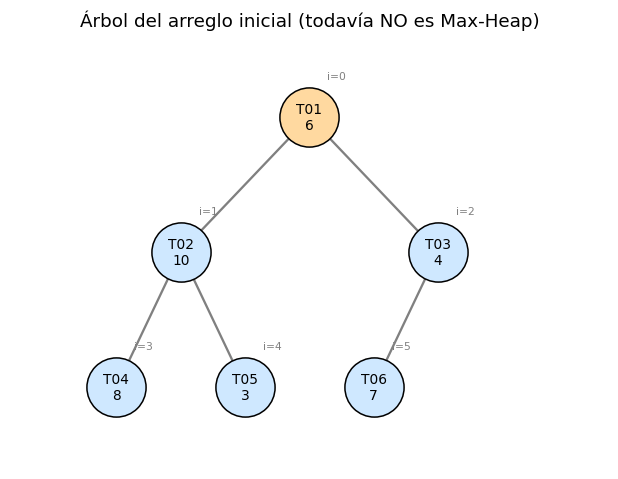


BUILD-MAX-HEAP paso a paso:
  max_heapify en i=2: [T01:6, T02:10, T06:7, T04:8, T05:3, T03:4]
  max_heapify en i=1: [T01:6, T02:10, T06:7, T04:8, T05:3, T03:4]
  max_heapify en i=0: [T02:10, T04:8, T06:7, T01:6, T05:3, T03:4]

Max-Heap resultante
  Arreglo: [T02:10, T04:8, T06:7, T01:6, T05:3, T03:4]
  ¿Cumple propiedad Max-Heap? True


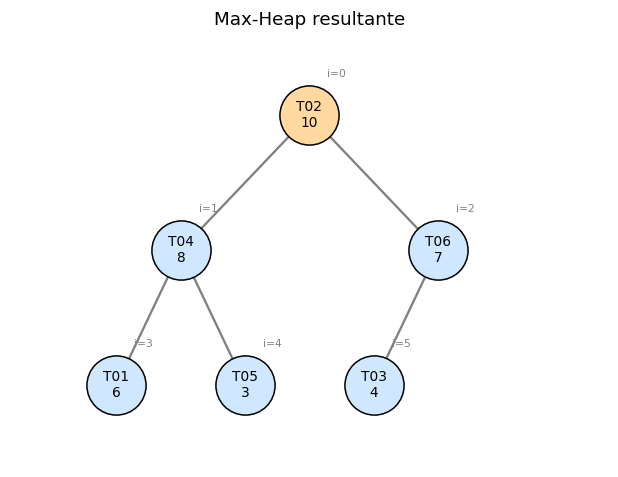

In [5]:

heap = list(arreglo_inicial)          
print("ARREGLO INICIAL (sin ordenar como heap)")
print("  Arreglo:", fmt(heap))
print("  ¿Cumple propiedad Max-Heap?", es_max_heap(heap))
dibujar_heap(heap, "Árbol del arreglo inicial (todavía NO es Max-Heap)")


print("\nBUILD-MAX-HEAP paso a paso:")
build_max_heap(heap, verbose=True)

print()
mostrar_heap(heap, "Max-Heap resultante")

## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
